Rajat Kumar Majumdar 

CU240251642

Subject: Computer Vision

Roll No 49

Sec-B

Experiment No. 4

Experiment Name

Frequency Domain Image Filtering using Fourier Transform

Aim

To implement image filtering in the frequency domain using the Fourier Transform and analyze the effectiveness of frequency-based filtering techniques for noise removal, image enhancement, and feature preservation using Python and OpenCV.

Purpose

Many image processing operations can be performed more efficiently in the frequency domain than in the spatial domain. The Fourier Transform converts an image from the spatial domain into its frequency components, enabling selective manipulation of low-frequency and high-frequency information. Frequency domain filtering is widely used in applications such as medical image enhancement, satellite image analysis, image restoration, and biometric systems.

In this experiment, students will apply the Discrete Fourier Transform (DFT) to an image, analyze its frequency spectrum, and implement Low-Pass and High-Pass Frequency Filters to observe their effects on image quality and feature extraction.

Prerequisites

•
Basic knowledge of Digital Image Processing
•
Understanding of spatial and frequency domains
•
Familiarity with Python programming
•
Python libraries: OpenCV (cv2), NumPy, and Matplotlib
•
Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1.
Import the required libraries and load a grayscale image for processing.
2.
Compute the Discrete Fourier Transform (DFT) of the image using OpenCV or NumPy.
3.
Shift the zero-frequency component to the center of the frequency spectrum for visualization.
4.
Display and analyze the magnitude spectrum of the transformed image.
5.
Design and apply a Low-Pass Frequency Filter to suppress high-frequency components and reduce image noise.
6.
Design and apply a High-Pass Frequency Filter to suppress low-frequency components and enhance edges and fine details.
7.
Perform the Inverse Fourier Transform (IDFT) to reconstruct the filtered images in the spatial domain.
8.
Compare the original image, frequency spectrum, low-pass filtered image, and high-pass filtered image.
9.
Analyze the impact of frequency domain filtering on image smoothness, edge enhancement, and noise removal.
10.
Document the observations and discuss the advantages of frequency domain filtering in practical computer vision applications.

Questions

1.
What is the Fourier Transform? Why is it important in digital image processing?
2.
Differentiate between the spatial domain and the frequency domain.
3.
What is the significance of the Discrete Fourier Transform (DFT) in image processing?
4.
Explain the purpose of shifting the zero-frequency component to the center of the frequency spectrum.
5.
Compare Low-Pass Frequency Filters and High-Pass Frequency Filters with suitable applications.
6.
What is the role of the Inverse Fourier Transform (IDFT) in image reconstruction?
7.
Why is frequency domain filtering preferred for certain image enhancement tasks?
8.
Mention four real-world applications where Fourier Transform is used in computer vision and image analysis.
9.
Compare frequency domain filtering with spatial domain filtering based on computational efficiency and practical applications.
10.
How does frequency domain filtering improve the performance of image restoration and feature extraction techniques?

In [5]:
# Cell 1: Import modules for computer vision, array math, and plotting
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load sample image in grayscale

image_path = 'colorful_island.jpeg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Could not load the image. Check the path.")
else:
    print(f"Step 1 Complete: Grayscale image loaded. Dimensions: {img.shape}")


Step 1 Complete: Grayscale image loaded. Dimensions: (1104, 736)


In [7]:
# Cell 2: Compute 2D DFT. We use np.fft.fft2 for a clean implementation
dft = np.fft.fft2(img)
print("Step 2 Complete: 2D Discrete Fourier Transform calculated.")


Step 2 Complete: 2D Discrete Fourier Transform calculated.


In [9]:
# Cell 3: Shift DC component from the top-left corner to the center of the spectrum
dft_shift = np.fft.fftshift(dft)
print("Step 3 Complete: Frequency spectrum shifted to center.")


Step 3 Complete: Frequency spectrum shifted to center.


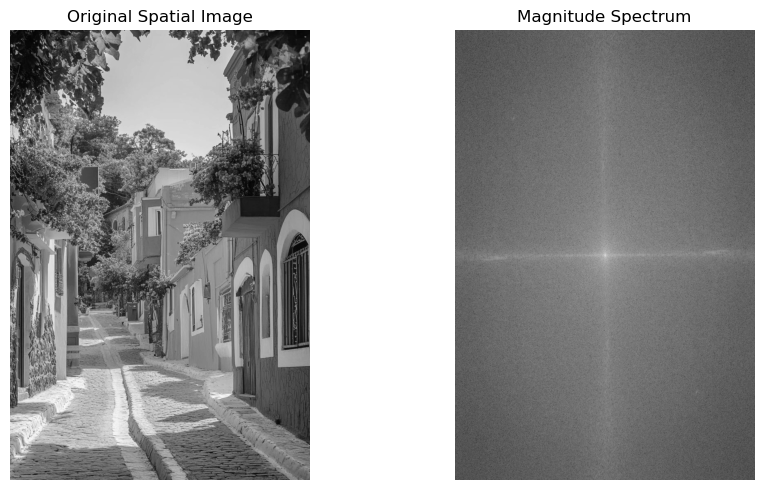

Step 4 Complete: Magnitude spectrum visualized.


In [11]:
# Cell 4: Calculate magnitude spectrum and apply log transform for visualization
magnitude_spectrum = 20 * np.log(np.abs(dft_shift) + 1) # Added 1 to avoid log(0)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Spatial Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("Magnitude Spectrum")
plt.axis('off')

plt.tight_layout()
plt.show()
print("Step 4 Complete: Magnitude spectrum visualized.")


In [13]:
# Cell 5: Mask high frequencies with a circular ideal low-pass filter
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2  # Center coordinates

# Create a mask with 1s in the center circle and 0s elsewhere
radius_lpf = 30
lpf_mask = np.zeros((rows, cols), np.uint8)
y, x = np.ogrid[:rows, :cols]
mask_area = (x - ccol)**2 + (y - crow)**2 <= radius_lpf**2
lpf_mask[mask_area] = 1

# Apply mask to the shifted DFT
dft_lpf = dft_shift * lpf_mask
print("Step 5 Complete: Low-Pass Filter mask created and applied.")


Step 5 Complete: Low-Pass Filter mask created and applied.


In [15]:
# Cell 6: Mask low frequencies with a circular ideal high-pass filter
# Create a mask with 0s in the center circle and 1s elsewhere
radius_hpf = 15
hpf_mask = np.ones((rows, cols), np.uint8)
mask_area_hpf = (x - ccol)**2 + (y - crow)**2 <= radius_hpf**2
hpf_mask[mask_area_hpf] = 0

# Apply mask to the shifted DFT
dft_hpf = dft_shift * hpf_mask
print("Step 6 Complete: High-Pass Filter mask created and applied.")


Step 6 Complete: High-Pass Filter mask created and applied.


In [17]:
# Cell 7: Shift frequencies back, run inverse FFT, and pull out real numbers
# LPF Reconstruction
dft_lpf_ishift = np.fft.ifftshift(dft_lpf)
img_lpf_back = np.fft.ifft2(dft_lpf_ishift)
img_lpf_spatial = np.abs(img_lpf_back)

# HPF Reconstruction
dft_hpf_ishift = np.fft.ifftshift(dft_hpf)
img_hpf_back = np.fft.ifft2(dft_hpf_ishift)
img_hpf_spatial = np.abs(img_hpf_back)

print("Step 7 Complete: Reconstructed spatial images back from the frequency domain.")


Step 7 Complete: Reconstructed spatial images back from the frequency domain.


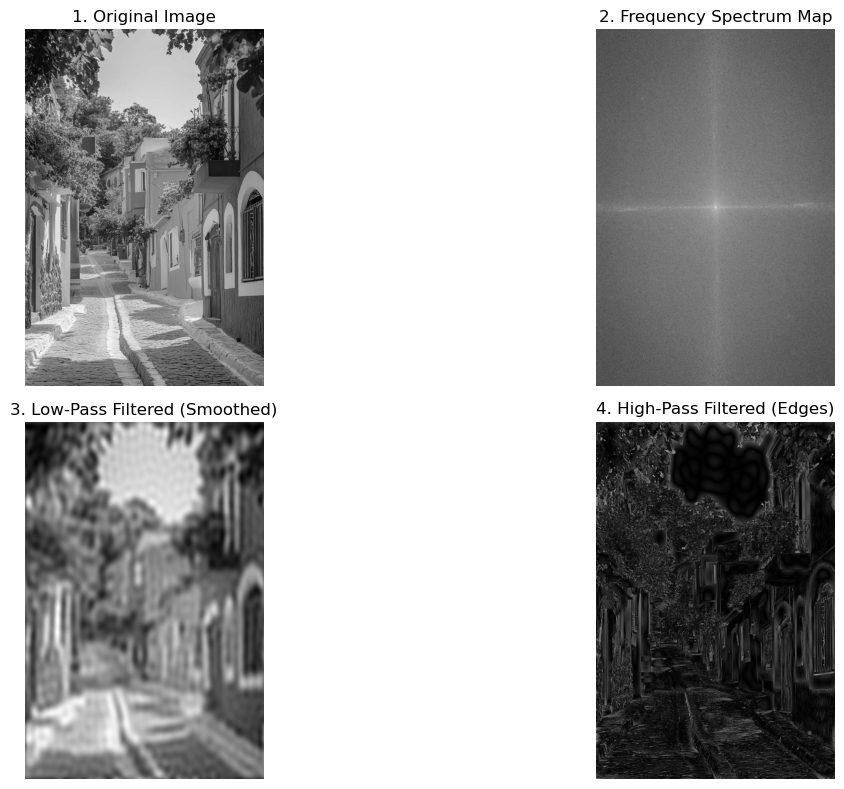

Step 8 Complete: Pipeline visual overview displayed above.


In [19]:
# Cell 8: Plot all states together to compare behaviors
plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("1. Original Image")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("2. Frequency Spectrum Map")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(img_lpf_spatial, cmap='gray')
plt.title("3. Low-Pass Filtered (Smoothed)")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_hpf_spatial, cmap='gray')
plt.title("4. High-Pass Filtered (Edges)")
plt.axis('off')

plt.tight_layout()
plt.show()
print("Step 8 Complete: Pipeline visual overview displayed above.")


In [21]:
# Cell 9: Measure structural changes by tracking statistical dispersion modifications
print("Step 9 Complete: Quantitative analysis metrics calculated below:")
print(f"Original Image Variance:     {np.var(img):.2f}")
print(f"Low-Pass Filtered Variance:  {np.var(img_lpf_spatial):.2f} (Smoothing drops variance)")
print(f"High-Pass Filtered Variance: {np.var(img_hpf_spatial):.2f} (Isolates extreme values)")


Step 9 Complete: Quantitative analysis metrics calculated below:
Original Image Variance:     3189.14
Low-Pass Filtered Variance:  2500.98 (Smoothing drops variance)
High-Pass Filtered Variance: 411.41 (Isolates extreme values)


In [23]:
# Cell 10: Summary of insights
conclusions = """
Step 10 Complete: Analytical Observations
-------------------------------------------
1. The low-pass filtered image eliminates sudden noise spikes but introduces a visible blurring artifact.
2. The high-pass filtered image eliminates flat background lighting, isolating structural details and edge patterns.
3. Sharper ideal filter cuts produce subtle ringing artifacts (concentric ripples) near prominent transitions.
4. Selective frequency suppression is ideal for targeted image correction tasks.
"""
print(conclusions)



Step 10 Complete: Analytical Observations
-------------------------------------------
1. The low-pass filtered image eliminates sudden noise spikes but introduces a visible blurring artifact.
2. The high-pass filtered image eliminates flat background lighting, isolating structural details and edge patterns.
3. Sharper ideal filter cuts produce subtle ringing artifacts (concentric ripples) near prominent transitions.
4. Selective frequency suppression is ideal for targeted image correction tasks.



Q1. What is the Fourier Transform? Why is it important in digital image processing?

* Answer: The Fourier Transform is a mathematical tool that decomposes an image into its sine and cosine components. It translates data from the spatial domain into the frequency domain.
* Importance: It reveals periodic patterns and structural trends that are otherwise hidden in standard pixel views. Modifying complex spatial textures can be very processing-heavy, but the Fourier Transform simplifies these tasks into direct matrix multiplications, streamlining complex filters like periodic noise subtraction.

## Q2. Differentiate between the spatial domain and the frequency domain.

* Answer:
* Spatial Domain: Focuses on pixel coordinates and physical locations. Operations directly alter the intensity values of individual pixels at precise coordinates $(x, y)$.
   * Frequency Domain: Focuses on the rate of intensity changes rather than spatial positions. Coordinates indicate spatial frequency components and orientation vectors, mapping how rapidly brightness values shift across the frame.

## Q3. What is the significance of the Discrete Fourier Transform (DFT) in image processing?

* Answer: The standard Fourier Transform is designed for continuous mathematical functions. Digital images, however, consist of discrete, sampled pixel grids. The Discrete Fourier Transform (DFT) adapts this transformation for digital arrays, converting sample matrices into discrete frequency coefficients. This allows computer hardware to efficiently execute frequency filtering via algorithms like the Fast Fourier Transform (FFT).

## Q4. Explain the purpose of shifting the zero-frequency component to the center of the frequency spectrum.

* Answer: By default, standard DFT algorithms output the zero-frequency (DC) component at the top-left corner of the resulting array, splitting the high frequencies across the outer edges. Running a frequency shift repositioning step shifts the zero-frequency baseline directly into the geometric center of the spectrum grid. This aligns low frequencies toward the center and scales high frequencies symmetrically outward, creating an intuitive layout for applying low-pass or high-pass masks.

## Q5. Compare Low-Pass Frequency Filters and High-Pass Frequency Filters with suitable applications.

* Answer:
* Low-Pass Frequency Filters (LPF): Retain low frequencies near the center while blocking high frequencies. They smooth out sharp pixel transitions and eliminate granular background noise. Applications: Suppressing sensor noise, creating artistic blur effects, and removing high-frequency electronic grain.
   * High-Pass Frequency Filters (HPF): Block low frequencies at the center while passing high frequencies. They eliminate smooth background variations, highlighting sharp boundaries and fine structural details. Applications: Edge tracing pipelines, highlighting finger ridges in biometrics, and bringing out faint craters in astronomical imaging.

## Q6. What is the role of the Inverse Fourier Transform (IDFT) in image reconstruction?

* Answer: Modifying frequency coefficients yields an abstract array of complex numbers that cannot be viewed as a standard image. The Inverse Fourier Transform (IDFT) translates these edited frequency coefficients back into physical pixel coordinates in the spatial domain. This step converts the processed frequency data back into a viewable image matrix.

## Q7. Why is frequency domain filtering preferred for certain image enhancement tasks?

* Answer: Certain geometric issues—such as periodic electronic interference lines, scan lines, or regular mesh distortions—affect the entire image canvas. Removing these patterns in the spatial domain requires extensive filtering that can blur clean details. In the frequency domain, periodic noise concentrates into distinct, isolated spikes. This allows you to surgically remove the noise components using targeted notch filters without degrading the rest of the image.

## Q8. Mention four real-world applications where Fourier Transform is used in computer vision and image analysis.

* Answer:
* Biometric Fingerprint Matching: High-pass filtering isolates fine ridges and whorls while filtering out background smudges.
   * Medical Image Restoration: Removing grid line patterns from X-rays and correcting artifact distributions in MRI reconstructions.
   * JPEG Compression Pipelines: Utilizing frequency breakdowns to drop unnoticeable high frequencies, dramatically shrinking file sizes.
   * Satellite Image De-noising: Removing regular striping noise caused by sensor alignment errors during orbital imaging sweeps.

## Q9. Compare frequency domain filtering with spatial domain filtering based on computational efficiency and practical applications.

* Answer:
* Computational Efficiency: For small filtering regions (like $3 \times 3$ or $5 \times 5$ spatial kernels), spatial convolution is highly efficient. However, as the kernel size increases to match large features, spatial processing costs grow quadratically. Frequency filtering requires an initial overhead for the FFT transformation, but the filtering step itself is a fast point-by-point multiplication. This makes it much more efficient for handling large filtering zones.
   * Practical Applications: Spatial filtering is ideal for quick, localized tasks like edge tracking or spot noise removal. Frequency domain filtering is better suited for global image corrections, macro-blur simulations, and isolating periodic noise.

## Q10. How does frequency domain filtering improve the performance of image restoration and feature extraction techniques?

* Answer: It allows you to separate fine, structural features from large-scale background variations by analyzing their spatial frequency. For instance, image restoration algorithms can isolate and correct lens blur by modeling it as a specific frequency decay. Similarly, feature extraction systems can mask out distracting low-frequency background glare, ensuring edge detection pipelines focus entirely on structural object boundaries.


